In [1]:
import pandas as pd

In [2]:
!ls ../dataset_kraken/


family_name_ids.csv  genus_name_ids.csv  species_name_ids.csv
family_seqs.csv      genus_seqs.csv	 species_seqs.csv


In [3]:
species_labels = pd.read_csv("../dataset_kraken/species_name_ids.csv")


In [4]:
species_labels.head()

,species,id
0,Alphafusarivirus rutstroemiae,1
1,Alphafusarivirus macrophominae,2
2,Alphafusarivirus ioaponiae,3
3,Alphafusarivirus auriculariae,4
4,Alphafusarivirus penicilli,5


In [10]:
ictv_master = pd.read_excel("ICTV_Master_Species_List_2025_MSL41.v1.xlsx",sheet_name='MSL')
ictv_renames = pd.read_excel("ICTV_Master_Species_List_2025_MSL41.v1.xlsx",sheet_name='Taxa Renamed or Abolished')

In [11]:
ictv_master.head()

,Sort,Realm,Subrealm,Kingdom,Subkingdom,Phylum,Subphylum,Class,Subclass,Order,...,Family,Subfamily,Genus,Subgenus,Species,ICTV_ID,Genome,Last Change,MSL of Last Change,Proposal for Last Change
0,1,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Chiyouviridae,NaN,Wargodvirus,NaN,Wargodvirus xiongnu,ICTV202420188,dsDNA,"New,",40,2024.005A.Bathyarchaeia_4newfam.zip
1,2,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Alphalipothrixvirus,NaN,Alphalipothrixvirus beppuense,ICTV201908643,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip
2,3,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Alphalipothrixvirus,NaN,Alphalipothrixvirus umijigokuense,ICTV201908644,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip
3,4,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Betalipothrixvirus,NaN,Betalipothrixvirus acidiani,ICTV20094000,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip
4,5,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Betalipothrixvirus,NaN,Betalipothrixvirus hveragerdiense,ICTV20041365,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip


In [12]:
ictv_renames.head()

,ICVD_ID,Rank,Change,Old Name,New Name,proposal
0,ICTV201907161,realm,Renamed,Monodnaviria,Floreoviria,2025.002G.Monodnaviria_reorg_4nr.zip
1,ICTV201907168,class,Abolished,Monodnaviria;Sangervirae;Phixviricota;Malgrand...,NaN,2025.043B.Microviricetes_reorg.zip
2,ICTV201907169,order,Abolished,Monodnaviria;Sangervirae;Phixviricota;Malgrand...,NaN,2025.043B.Microviricetes_reorg.zip
3,ICTV19780013,family>class,"Renamed,Promoted",Monodnaviria;Sangervirae;Phixviricota;Malgrand...,Volvereviria;Sangervirae;Phixviricota;Microvir...,2025.043B.Microviricetes_reorg.zip
4,ICTV202419628,family,Renamed,Riboviria;Orthornavirae;Orpoviricetes;Bormycov...,Riboviria;Orthornavirae;Orpoviricetes;Bormycov...,2025.004F.Deltanormycoviridae_rename.zip


In [8]:
import pandas as pd
from Bio import Entrez
import time
import re
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

def fetch_ncbi_taxonomy_parallel(df, email, api_key=None, species_col='species', max_retries=5, max_workers=None):
    """
    Parallelized fetcher with cleaning, retries, and rate-limit management.
    """
    Entrez.email = email
    if api_key:
        Entrez.api_key = api_key
    
    # Auto-set workers based on NCBI limits if not provided
    if max_workers is None:
        max_workers = 10 if api_key else 3

    print(f"using {max_workers} workers")
    def get_single_species(index, species):
        """Worker function for a single species lookup."""
        # 1. Pre-cleaning
        if re.match(r'^\d{4}$|^[A-Z]{1,3}$|^\d+$', str(species).strip()):
            return index, "METADATA_SKIP", "METADATA_SKIP", "METADATA_SKIP", "Invalid Name"

        for attempt in range(max_retries):
            try:
                # Search
                search_handle = Entrez.esearch(db="taxonomy", term=species)
                search_record = Entrez.read(search_handle)
                search_handle.close()
                
                if not search_record["IdList"]:
                    return index, None, None, None, "Not Found"
                
                tax_id = search_record["IdList"][0]
                
                # Fetch Lineage
                fetch_handle = Entrez.efetch(db="taxonomy", id=tax_id, retmode="xml")
                fetch_record = Entrez.read(fetch_handle)
                fetch_handle.close()
                
                lineage_nodes = fetch_record[0].get("LineageEx", [])
                full_path = " / ".join([n.get("ScientificName") for n in lineage_nodes])
                
                found = {'order': (None, None), 'family': (None, None), 'genus': (None, None)}
                for node in lineage_nodes:
                    rank = node.get("Rank")
                    if rank in found:
                        found[rank] = (node.get("TaxId"), node.get("ScientificName"))
                
                return index, found['order'], found['family'], found['genus'], full_path
                
            except Exception as e:
                if attempt < max_retries - 1:
                    time.sleep((attempt + 1) * 2)
                    continue
                return index, "ERROR", "ERROR", "ERROR", f"Fatal: {str(e)}"

    # --- Execution ---
    results_map = {}
    species_list = list(enumerate(df[species_col]))

    print(f"Starting parallel fetch with {max_workers} workers...")
    
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        # Submit all tasks
        futures = {executor.submit(get_single_species, i, name): i for i, name in species_list}
        
        for future in tqdm(as_completed(futures), total=len(futures), desc="Processing Species"):
            idx, o, f, g, path = future.result()
            results_map[idx] = (o, f, g, path)
            # Small throttle to ensure we don't burst past NCBI limits
            time.sleep(1 / max_workers)

    # --- Reassembling Data ---
    df_result = df.copy()
    
    # Initialize lists to be filled in correct order
    order_ids, family_ids, genus_ids, full_paths = [], [], [], []
    order_map_data, family_map_data, genus_map_data = [], [], []

    for i in range(len(df)):
        o, f, g, path = results_map[i]
        
        # Unpack tuples (TaxId, Name)
        order_ids.append(o[0] if isinstance(o, tuple) else o)
        family_ids.append(f[0] if isinstance(f, tuple) else f)
        genus_ids.append(g[0] if isinstance(g, tuple) else g)
        full_paths.append(path)

        # Collect for auxiliary DFs
        if isinstance(o, tuple) and o[0]: order_map_data.append({'label': o[1], 'id': o[0]})
        if isinstance(f, tuple) and f[0]: family_map_data.append({'label': f[1], 'id': f[0]})
        if isinstance(g, tuple) and g[0]: genus_map_data.append({'label': g[1], 'id': g[0]})

    df_result['order_id'] = order_ids
    df_result['family_id'] = family_ids
    df_result['genus_id'] = genus_ids
    df_result['full_lineage'] = full_paths

    return {
        'main_df': df_result,
        'order_df': pd.DataFrame(order_map_data).drop_duplicates().reset_index(drop=True),
        'family_df': pd.DataFrame(family_map_data).drop_duplicates().reset_index(drop=True),
        'genus_df': pd.DataFrame(genus_map_data).drop_duplicates().reset_index(drop=True)
    }
# Call example


In [10]:
results = fetch_ncbi_taxonomy_parallel(df=species_labels, email="matheuslimaaa13@gmail.com",api_key="602c9bd77a872b9b1fce84e70d8c7d08bd09")

using 10 workers
Starting parallel fetch with 10 workers...


Processing Species: 100%|██████████| 13683/13683 [50:18<00:00,  4.53it/s] 


In [11]:
# Assuming 'results' is the dictionary returned by the function
df_final = results['main_df']

# Filter for rows where any of the taxonomy ID columns are None/NaN
none_values_df = df_final[
    df_final['order_id'].isna() | 
    df_final['family_id'].isna() | 
    df_final['genus_id'].isna()
]

# Display the results
print(f"Total rows with missing data: {len(none_values_df)}")
print(none_values_df)

Total rows with missing data: 6183
                                          species     id order_id family_id  \
34                Nigrospora oryzae fusarivirus 1     35  2732549   1661063   
35             Sodiomyces alkalinus fusarivirus 1     36  2732549   1661063   
54            Verticillium dahliae partitivirus 1     55  2732549     11012   
55                        Spinach cryptic virus 1     56  2732549     11012   
56               Rhizoctonia solani dsRNA virus 2     57  2732549     11012   
...                                           ...    ...      ...       ...   
13677      Ctenophore-associated circular virus 1  13678     None      None   
13678  Ustilaginoidea virens nonsegmented virus 2  13679     None      None   
13679                            uncultured virus  13680     None      None   
13681                 Sanxia picorna-like virus 8  13682     None      None   
13682                   Beihai sea slater virus 3  13683     None      None   

      genus_id  

In [12]:
failed_species = none_values_df['species'].tolist()
print("Species with missing taxonomic ranks:", failed_species)

Species with missing taxonomic ranks: ['Nigrospora oryzae fusarivirus 1', 'Sodiomyces alkalinus fusarivirus 1', 'Verticillium dahliae partitivirus 1', 'Spinach cryptic virus 1', 'Rhizoctonia solani dsRNA virus 2', 'Dill cryptic virus 1', 'Pseudogymnoascus destructans partitivirus-pa', 'Fragaria chiloensis cryptic virus', 'Raphanus sativus cryptic virus 3', 'Sclerotinia sclerotiorum partitivirus S', 'Botryotinia fuckeliana partitivirus 1', 'Bipolaris maydis partitivirus 2', 'Penicillium aurantiogriseum partitivirus 1', 'Ustilaginoidea virens partitivirus 2', 'Sophora japonica powdery mildew-associated partitivirus', 'Sinapis alba cryptic virus 1', 'Raphanus sativus cryptic virus 2', 'Raphanus sativus cryptic virus 1', 'Red clover cryptic virus 1', 'Rose cryptic virus 1', 'Aspergillus fumigatus partitivirus 2', 'Melon partitivirus', 'Persimmon cryptic virus', 'Carnation cryptic virus 3', 'Bipolaris maydis partitivirus 1', 'Fusarium poae partitivirus 2', 'Rosellinia necatrix partitivirus 

In [13]:
def backfill_taxonomy(row):
    # If Genus is missing, try to create a placeholder from the Family or Order
    if pd.isna(row['genus_id']):
        if not pd.isna(row['family_id']):
            return f"fam_{row['family_id']}_unclassified"
        if not pd.isna(row['order_id']):
            return f"ord_{row['order_id']}_unclassified"
        return "incertae_sedis" # Truly unclassified
    return row['genus_id']

results['main_df']['final_label'] = results['main_df'].apply(backfill_taxonomy, axis=1)

In [17]:
!pwd

/home/mlima/workspace/cnn_kraken


In [18]:
import os

# 1. Definir o diretório de saída
output_dir = 'data_taxonomy_parquet'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 2. Salvar cada DataFrame do dicionário de resultados
# Onde 'results' é o dicionário retornado pela função de busca
for df_name, df in results.items():
    file_path = os.path.join(output_dir, f"{df_name}.parquet")
    
    # Usamos o engine 'pyarrow' que lida muito bem com valores nulos (None)
    df.to_parquet(file_path, index=False, engine='pyarrow', compression='snappy')
    
    print(f"Arquivo salvo com sucesso: {file_path}")

# Exemplo de como carregar depois:
# df_main = pd.read_parquet('data_taxonomy_parquet/main_df.parquet')

Arquivo salvo com sucesso: data_taxonomy_parquet/main_df.parquet
Arquivo salvo com sucesso: data_taxonomy_parquet/order_df.parquet
Arquivo salvo com sucesso: data_taxonomy_parquet/family_df.parquet
Arquivo salvo com sucesso: data_taxonomy_parquet/genus_df.parquet


In [6]:
df_main = pd.read_parquet('data_taxonomy_parquet/main_df.parquet')
df_family = pd.read_parquet('data_taxonomy_parquet/family_df.parquet')
df_genus = pd.read_parquet('data_taxonomy_parquet/genus_df.parquet')
df_order = pd.read_parquet('data_taxonomy_parquet/order_df.parquet')
df_species = pd.read_csv("data_taxonomy_parquet/species_name_ids.csv")


In [7]:
df_main['id']

0            1
1            2
2            3
3            4
4            5
         ...  
13678    13679
13679    13680
13680    13681
13681    13682
13682    13683
Name: id, Length: 13683, dtype: int64

In [8]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import joblib # Para salvar os encoders

def normalize_and_sync(df_main, lookup_dfs, species_df):
    encoders = {}
    
    for col_name, lookup_df in lookup_dfs.items():
        le = LabelEncoder()
        
        # 1. Fit apenas nos IDs válidos da tabela de referência
        valid_ids = lookup_df['id'].dropna().unique().astype(str)
        le.fit(valid_ids)
        
        # 2. Atualiza a tabela de lookup
        lookup_df['normalized_id'] = le.transform(lookup_df['id'].astype(str))
        
        # 3. Máscara Refinada: Só transforma se NÃO for nulo E se o ID existir no encoder
        # Isso ignora automaticamente 'METADATA_SKIP' ou erros de conexão
        is_valid_id = df_main[col_name].astype(str).isin(le.classes_)
        
        # Inicializa a coluna com NaN
        df_main[f'norm_{col_name}'] = pd.NA 
        
        # Aplica a transformação apenas nos índices válidos
        if is_valid_id.any():
            df_main.loc[is_valid_id, f'norm_{col_name}'] = le.transform(
                df_main.loc[is_valid_id, col_name].astype(str)
            )
        
        encoders[col_name] = le

    # --- Normalização de Species ---
    le_species = LabelEncoder()
    # Garante que estamos usando IDs de species válidos
    valid_species_ids = species_df['id'].dropna().unique().astype(str)
    le_species.fit(valid_species_ids)
    
    species_df['normalized_id'] = le_species.transform(species_df['id'].astype(str))
    
    # Mapeamento seguro para o df_main
    is_valid_species = df_main['id'].astype(str).isin(le_species.classes_)
    df_main['norm_species_id'] = pd.NA
    
    if is_valid_species.any():
        df_main.loc[is_valid_species, 'norm_species_id'] = le_species.transform(
            df_main.loc[is_valid_species, 'id'].astype(str)
        )
    
    encoders['species'] = le_species
    
    return df_main, encoders

# --- Execução ---

# Dicionário relacionando coluna do df_main -> dataframe de lookup
tax_configs = {
    'order_id': df_order,
    'family_id': df_family,
    'genus_id': df_genus
}

df_main, all_encoders = normalize_and_sync(df_main, tax_configs, df_species)

# 3. Salvar os Encoders (Crucial para o seu Mestrado!)
# Sem isso, você não consegue "traduzir" as predições do modelo depois
joblib.dump(all_encoders, 'data_taxonomy_parquet/label_encoders.joblib')

print("Normalização concluída e encoders salvos.")

Normalização concluída e encoders salvos.


In [9]:
# --- Resultado ---
print("Exemplo do df_main normalizado:")
print(df_main.head())

Exemplo do df_main normalizado:
                          species  id order_id family_id genus_id  \
0   Alphafusarivirus rutstroemiae   1  2732549   1661063  2946790   
1  Alphafusarivirus macrophominae   2  2732549   1661063  2946790   
2      Alphafusarivirus ioaponiae   3  2732549   1661063  2946790   
3   Alphafusarivirus auriculariae   4  2732549   1661063  2946790   
4      Alphafusarivirus penicilli   5  2732549   1661063  2946790   

                                        full_lineage final_label  \
0  Viruses / Riboviria / Orthornavirae / Pisuviri...     2946790   
1  Viruses / Riboviria / Orthornavirae / Pisuviri...     2946790   
2  Viruses / Riboviria / Orthornavirae / Pisuviri...     2946790   
3  Viruses / Riboviria / Orthornavirae / Pisuviri...     2946790   
4  Viruses / Riboviria / Orthornavirae / Pisuviri...     2946790   

  norm_order_id norm_family_id norm_genus_id norm_species_id  
0            37             51          1953               0  
1            37   

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def print_taxonomy_stats(df):
    levels = {
        'Order': 'norm_order_id',
        'Family': 'norm_family_id',
        'Genus': 'norm_genus_id',
        'Species': 'norm_species_id'
    }
    
    print(f"{'Nível':<10} | {'Total Válido':<15} | {'Classes Únicas':<15} | {'% Cobertura':<12}")
    print("-" * 60)
    
    total_rows = len(df)
    
    for label, col in levels.items():
        valid_count = df[col].notna().sum()
        unique_classes = df[col].nunique()
        coverage = (valid_count / total_rows) * 100
        
        print(f"{label:<10} | {valid_count:<15} | {unique_classes:<15} | {coverage:<12.2f}%")

# Execução
print_taxonomy_stats(df_main)

Nível      | Total Válido    | Classes Únicas  | % Cobertura 
------------------------------------------------------------
Order      | 8031            | 84              | 58.69       %
Family     | 9643            | 300             | 70.47       %
Genus      | 11586           | 2896            | 84.67       %
Species    | 13683           | 13683           | 100.00      %


/tmp/ipykernel_1987792/2699301124.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_stats, x='Nível', y='Cobertura (%)', palette='viridis', ax=ax1, alpha=0.7)


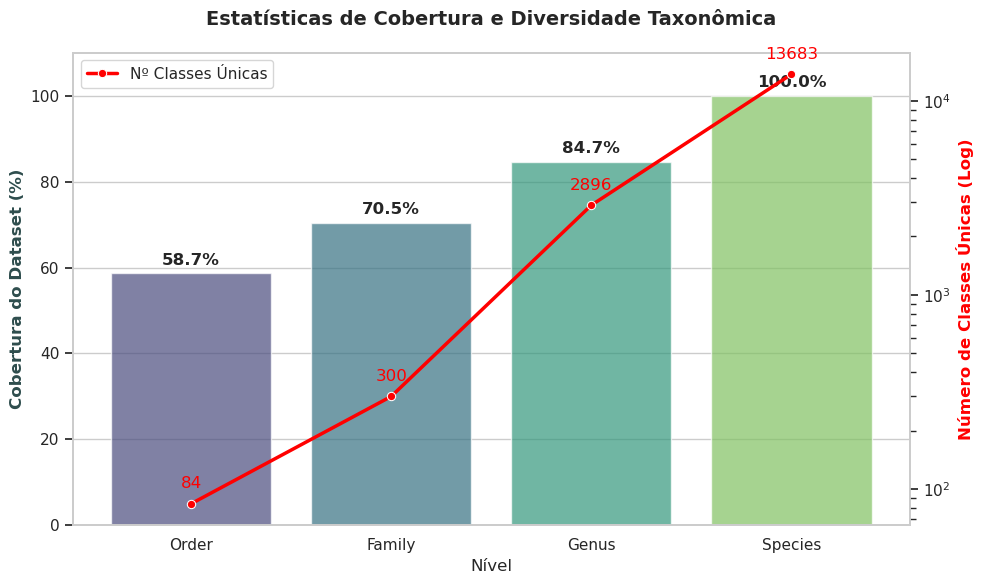

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_taxonomy_stats(df):
    levels = {
        'Order': 'norm_order_id',
        'Family': 'norm_family_id',
        'Genus': 'norm_genus_id',
        'Species': 'norm_species_id'
    }
    
    # 1. Preparação dos Dados
    stats_list = []
    total_rows = len(df)
    
    for label, col in levels.items():
        valid_count = df[col].notna().sum()
        unique_classes = df[col].nunique()
        coverage = (valid_count / total_rows) * 100
        stats_list.append({
            'Nível': label,
            'Cobertura (%)': coverage,
            'Classes Únicas': unique_classes
        })
    
    df_stats = pd.DataFrame(stats_list)

    # 2. Configuração do Gráfico (Dois eixos Y)
    sns.set_theme(style="whitegrid")
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Gráfico de Barras: Cobertura (%)
    sns.barplot(data=df_stats, x='Nível', y='Cobertura (%)', palette='viridis', ax=ax1, alpha=0.7)
    ax1.set_ylim(0, 110)
    ax1.set_ylabel('Cobertura do Dataset (%)', fontweight='bold', color='#2e4d4d')
    ax1.set_title('Estatísticas de Cobertura e Diversidade Taxonômica', fontsize=14, fontweight='bold', pad=20)

    # Eixo Secundário: Classes Únicas (Escala Logarítmica para lidar com a diferença de escala)
    ax2 = ax1.twinx()
    sns.lineplot(data=df_stats, x='Nível', y='Classes Únicas', marker='o', color='red', linewidth=2.5, ax=ax2, label='Nº Classes Únicas')
    ax2.set_yscale('log') # Escala logarítmica é essencial para ver de ~10 Ordens a 13.683 Espécies
    ax2.set_ylabel('Número de Classes Únicas (Log)', fontweight='bold', color='red')
    ax2.grid(False) # Evita sobreposição de grades

    # Anotações de Texto
    for i, row in df_stats.iterrows():
        ax1.text(i, row['Cobertura (%)'] + 2, f"{row['Cobertura (%)']:.1f}%", ha='center', fontweight='bold')
        ax2.text(i, row['Classes Únicas'] * 1.2, f"{row['Classes Únicas']}", color='red', ha='center')

    plt.tight_layout()
    plt.show()

# Execução no seu dataset principal (main_df.parquet) 
plot_taxonomy_stats(df_main)

/tmp/ipykernel_671365/3105337820.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=counts.values, ax=axes[i], palette='magma')
/tmp/ipykernel_671365/3105337820.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=counts.values, ax=axes[i], palette='magma')
/tmp/ipykernel_671365/3105337820.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=counts.values, ax=axes[i], palette='magma')


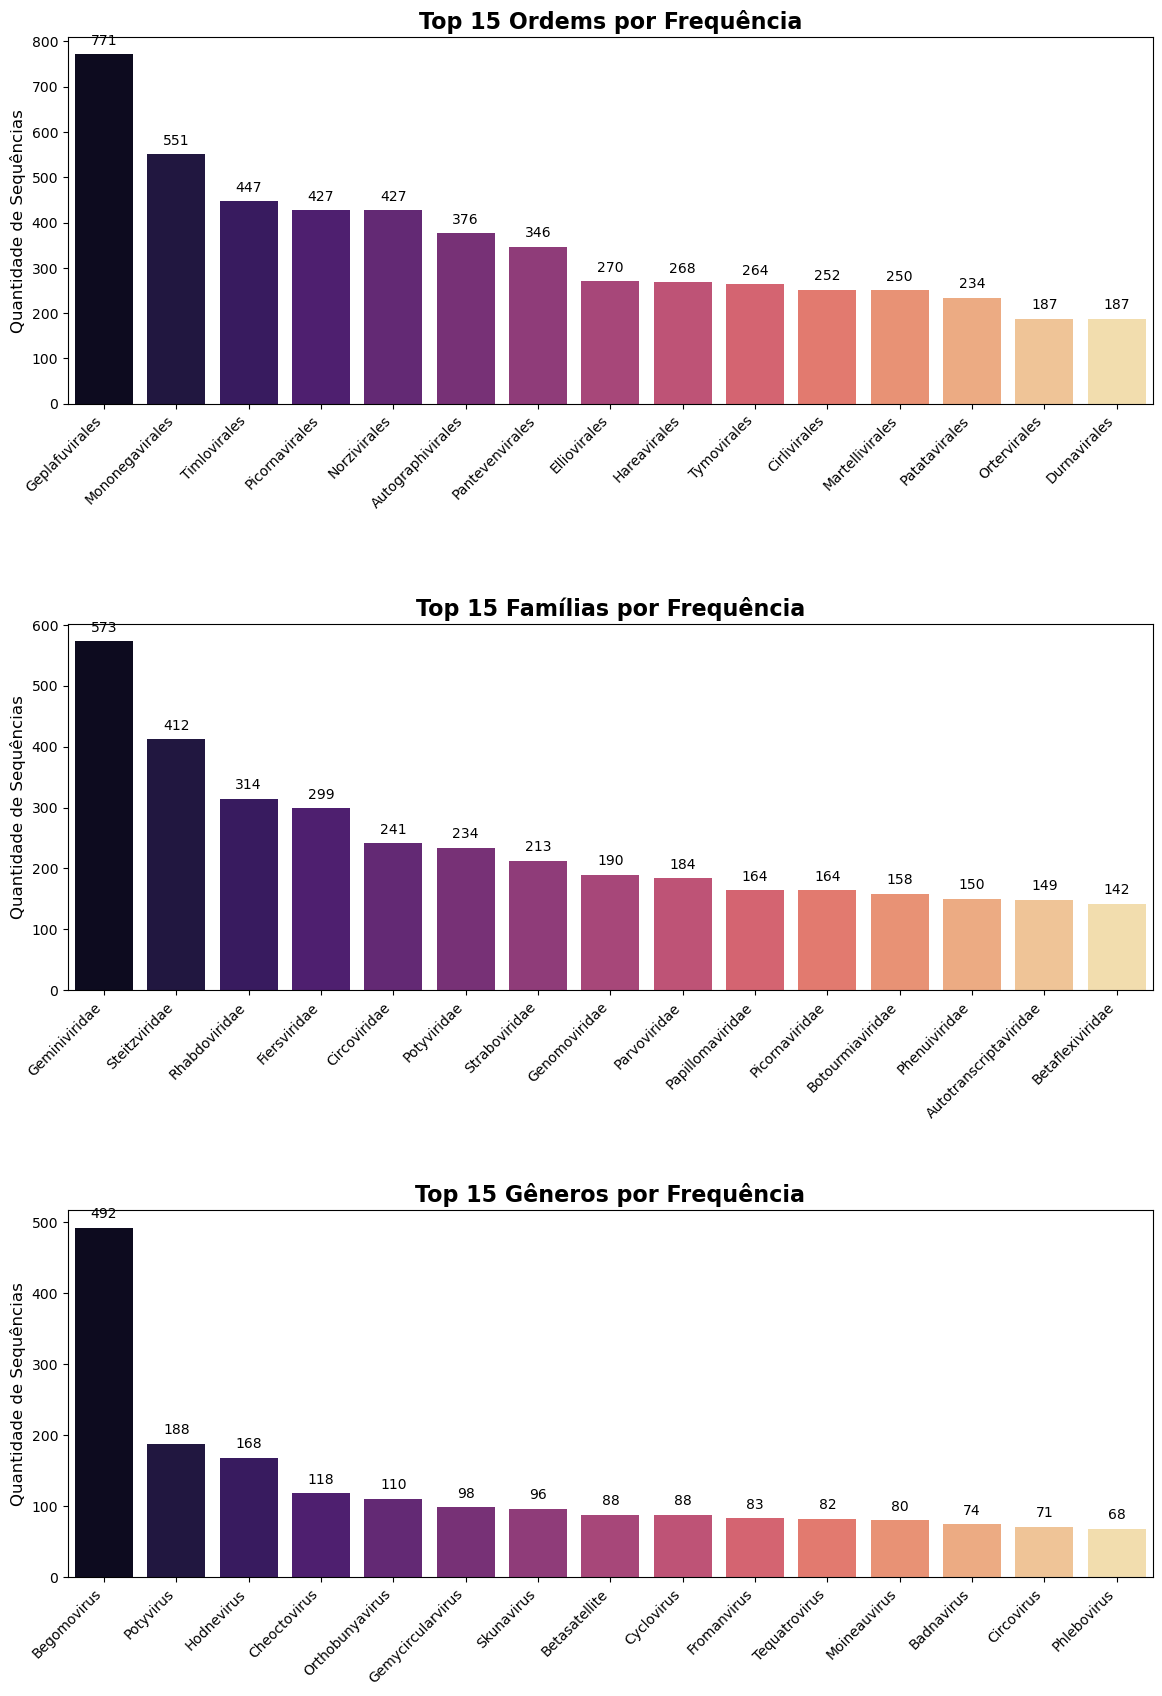

In [26]:
# Criando dicionários de mapeamento a partir dos seus dataframes de lookup
order_map = dict(zip(df_order['normalized_id'], df_order['label']))
family_map = dict(zip(df_family['normalized_id'], df_family['label']))
genus_map = dict(zip(df_genus['normalized_id'], df_genus['label']))

# Agrupando os mapeamentos para a função
mappings = {
    'norm_order_id': order_map,
    'norm_family_id': family_map,
    'norm_genus_id': genus_map
}

def plot_taxonomy_with_labels(df, mappings, top_n=15, desc:bool=True):
    levels = {
        'Ordem': 'norm_order_id',
        'Família': 'norm_family_id',
        'Gênero': 'norm_genus_id'
    }
    
    fig, axes = plt.subplots(len(levels), 1, figsize=(14, 20))
    plt.subplots_adjust(hspace=0.6) # Aumentado o espaço para os nomes rotacionados
    
    for i, (label_title, col_id) in enumerate(levels.items()):
        # 1. Conta a frequência dos IDs normalizados
        if desc:
            counts = df[col_id].value_counts().head(top_n)
        else:
            counts = df[col_id].value_counts().tail(top_n)
        
        # 2. Mapeia os IDs para os Nomes Científicos
        # Se o ID não estiver no mapa, mantém o ID original
        names = [mappings[col_id].get(int(idx), f"ID:{idx}") for idx in counts.index]
        
        # 3. Plotagem
        sns.barplot(x=names, y=counts.values, ax=axes[i], palette='magma')
        
        axes[i].set_title(f'Top {top_n} {label_title}s por Frequência', fontsize=16, fontweight='bold')
        axes[i].set_ylabel('Quantidade de Sequências', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45) # Rotaciona para caber nomes longos
        
        # Ajusta o alinhamento dos labels para a direita para facilitar a leitura
        for tick in axes[i].get_xticklabels():
            tick.set_horizontalalignment('right')

        # Adiciona os valores no topo das barras
        for p in axes[i].patches:
            axes[i].annotate(f'{int(p.get_height())}', 
                             (p.get_x() + p.get_width() / 2., p.get_height()), 
                             ha='center', va='center', xytext=(0, 10), 
                             textcoords='offset points', fontsize=10)

    plt.show()

# Execução
plot_taxonomy_with_labels(df_main, mappings, top_n=15)

/tmp/ipykernel_671365/3105337820.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=counts.values, ax=axes[i], palette='magma')
/tmp/ipykernel_671365/3105337820.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=counts.values, ax=axes[i], palette='magma')
/tmp/ipykernel_671365/3105337820.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=names, y=counts.values, ax=axes[i], palette='magma')


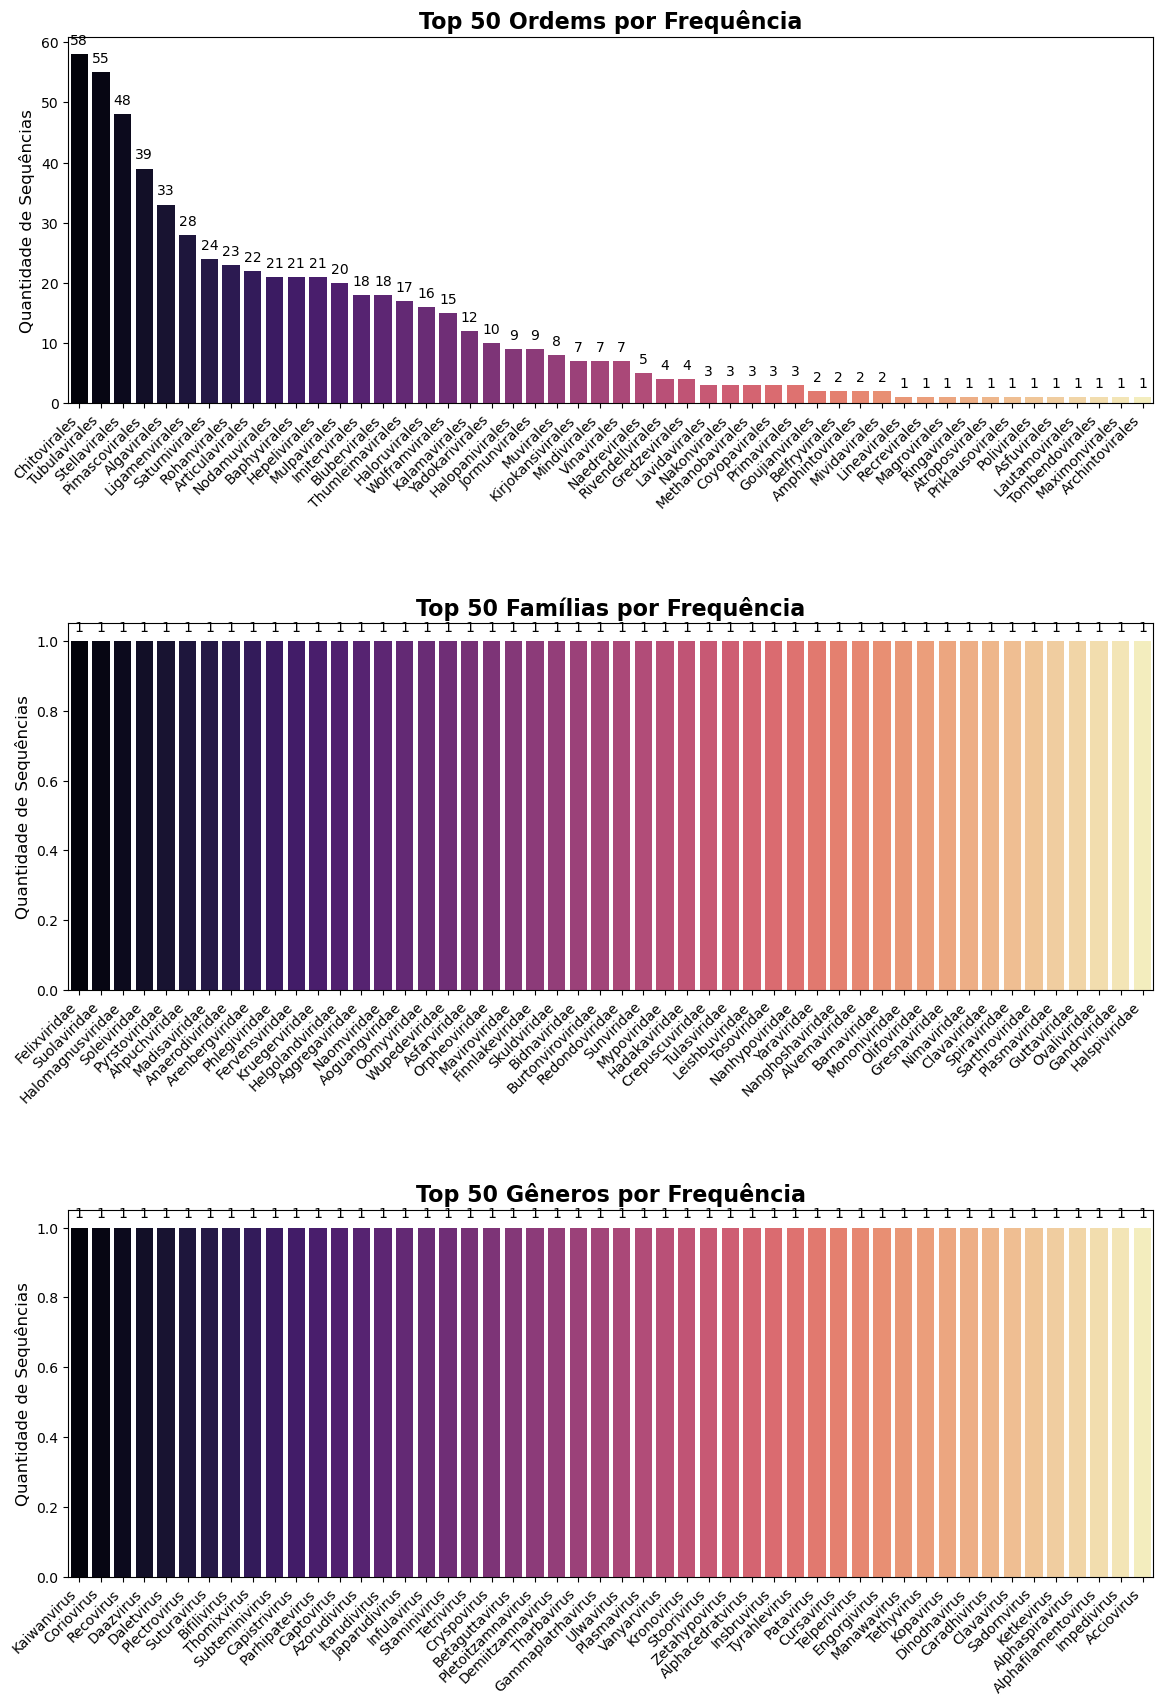

In [29]:
plot_taxonomy_with_labels(df_main, mappings, top_n=50,desc=False)

/tmp/ipykernel_1987792/3317711665.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


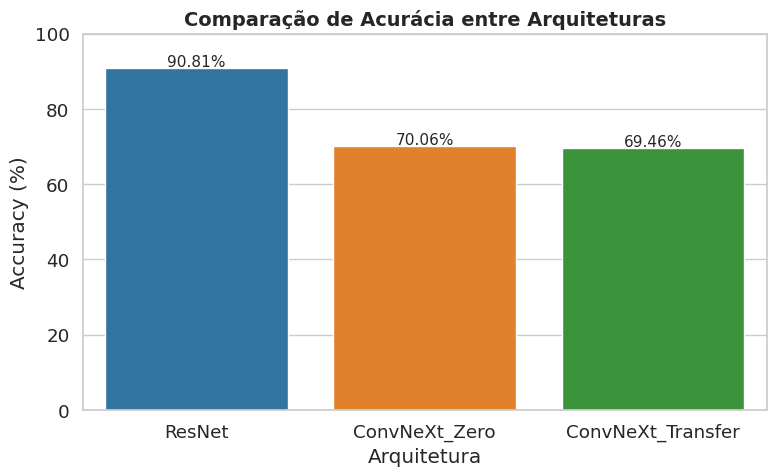

In [18]:
df_plt = pd.DataFrame({
    "names":["ResNet","ConvNeXt_Zero","ConvNeXt_Transfer"],
    "Acc": [90.809147 ,70.055545,69.463323]
})
# Estilo
sns.set(style="whitegrid", font_scale=1.2)

# Figura
plt.figure(figsize=(8, 5))

# Gráfico de barras
ax = sns.barplot(
    data=df_plt,
    x="names",
    y="Acc",
    palette=["#1f77b4", "#ff7f0e", "#2ca02c"]
)

# Adiciona valores nas barras
for i, v in enumerate(df_plt["Acc"]):
    ax.text(i, v + 0.5, f"{v:.2f}%", ha='center', fontsize=11)

# Configurações
plt.title("Comparação de Acurácia entre Arquiteturas", fontsize=14, weight='bold')
plt.xlabel("Arquitetura")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

# Melhor layout
plt.tight_layout()

# Exibe
plt.show()